# Taller: Preprocesamiento de Base de Datos - Heart Disease
**Asignatura:** Aprendizaje Automático (IIAR0004 - NRC 5414)  
**Docente:** Raúl Paredes, M. Sc.  
**Grupo:** Group 4 (Estudiante: Carlos Alberto Angulo Pizarro)  
**Autor:** Carlos Alberto Angulo Pizarro (`carlos.angulo.pizarro@udla.edu.ec`)  
**Fecha:** 14 de octubre de 2026  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Elnuget/taller-preprocesamiento-heart-disease/blob/main/Taller_Preprocesamiento_Heart_Disease_Carlos_Angulo.ipynb)
**Repositorio GitHub:** [https://github.com/Elnuget/taller-preprocesamiento-heart-disease](https://github.com/Elnuget/taller-preprocesamiento-heart-disease)  

---
### Objetivo General
Preparar un conjunto de datos clínicos (`Heart-Disease-Dirty.csv`) para su posterior utilización en un modelo de Machine Learning, aplicando técnicas de exploración, limpieza, transformación, codificación, división y escalamiento de datos, evitando problemas de fuga de información (*data leakage*).

## 1. Carga de Librerías y Conjunto de Datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Configuración estética de visualizaciones
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
np.random.seed(42)

# Carga de datos
df_raw = pd.read_csv('Heart-Disease-Dirty.csv')
print(f"Dimensiones iniciales del dataset crudo: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
df_raw.head()

Dimensiones iniciales del dataset crudo: 312 filas x 14 columnas


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,NaN,1.0,3.0,170.0,288.0,0.0,0.0,159.0,0.0,0.2,NaN,NaN,3.0,0.0
1,NaN,1.0,2.0,150.0,168.0,0.0,1.0,174.0,0.0,NaN,2.0,0.0,2.0,1.0
2,45.0,1.0,0.0,115.0,260.0,0.0,0.0,185.0,0.0,0.0,NaN,0.0,2.0,1.0
3,NaN,0.0,2.0,NaN,265.0,1.0,0.0,130.0,0.0,0.0,2.0,1.0,2.0,1.0
4,71.0,0.0,1.0,160.0,302.0,0.0,1.0,162.0,0.0,0.4,2.0,2.0,2.0,1.0


## 2. Exploración y Comprensión del Dataset (Criterio 1 - Rúbrica)
Se analiza exhaustivamente la estructura, tipos de variables detectadas, presencia de duplicados, estadísticos y distribución de la variable objetivo (`target`).

In [2]:
print("=== Estructura y tipos declarados ===")
df_raw.info()

print("\n=== Registros duplicados detectados ===")
print(f"Filas duplicadas exactas: {df_raw.duplicated().sum()}")

print("\n=== Distribución de la variable objetivo (target) ===")
print(df_raw['target'].value_counts(dropna=False))

=== Estructura y tipos declarados ===
<class 'pandas.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       288 non-null    str    
 1   sex       297 non-null    str    
 2   cp        298 non-null    float64
 3   trestbps  297 non-null    float64
 4   chol      297 non-null    float64
 5   fbs       297 non-null    float64
 6   restecg   296 non-null    float64
 7   thalach   297 non-null    float64
 8   exang     297 non-null    float64
 9   oldpeak   296 non-null    float64
 10  slope     296 non-null    float64
 11  ca        295 non-null    float64
 12  thal      295 non-null    float64
 13  target    297 non-null    float64
dtypes: float64(12), str(2)
memory usage: 34.3 KB

=== Registros duplicados detectados ===
Filas duplicadas exactas: 6

=== Distribución de la variable objetivo (target) ===
target
1.0    161
0.0    136
NaN     15


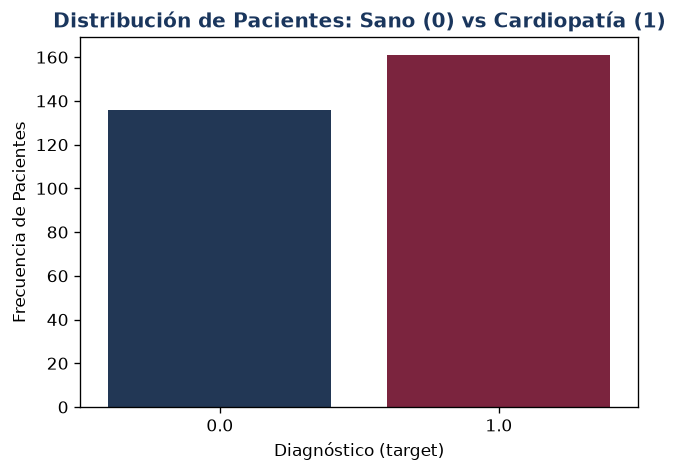

In [3]:
# Visualización de la variable objetivo en los casos etiquetados
plt.figure(figsize=(6, 4))
valid_targets = pd.to_numeric(df_raw['target'], errors='coerce').dropna()
sns.countplot(x=valid_targets, hue=valid_targets, palette=['#1A365D', '#8A1538'], legend=False)
plt.title('Distribución de Pacientes: Sano (0) vs Cardiopatía (1)', fontsize=12, fontweight='bold', color='#1A365D')
plt.xlabel('Diagnóstico (target)')
plt.ylabel('Frecuencia de Pacientes')
plt.show()

## 3. Identificación y Tratamiento de Problemas de Calidad (Criterio 2 - Rúbrica)
- **Duplicados:** Se eliminan 6 observaciones idénticas para evitar sobreajuste y ponderaciones espurias.
- **Ruido textual y unidades:** Se limpian tokens como `'ERROR'`, `'unknown'` y unidades como `'56.0 mg'` convirtiéndolas a float.
- **Target Nulo:** Se eliminan las 15 filas sin etiqueta. En aprendizaje supervisado no es válido imputar la variable objetivo, pues inventaría etiquetas clínicas artificiales.
- **Imputación de predictoras:** Se imputan numéricas con la mediana y categóricas/binarias con la moda.

In [4]:
df = df_raw.copy()

# 1. Eliminación justificada de duplicados
df = df.drop_duplicates()
print(f"Dimensiones tras eliminar duplicados: {df.shape}")

# 2. Limpieza de texto contaminado y unidades (ej. 'mg')
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].replace(['ERROR', 'unknown', '?'], np.nan)
        df[col] = df[col].astype(str).str.replace(' mg', '', regex=False)
        df[col] = df[col].replace('nan', np.nan)
        df[col] = pd.to_numeric(df[col], errors='coerce')

# 3. Tratamiento riguroso de target faltante: purga de filas sin etiqueta clínica
df = df.dropna(subset=['target'])
df['target'] = df['target'].astype(int)
print(f"Dimensiones tras purgar registros sin variable objetivo: {df.shape}")

# 4. Corrección de anomalías biológicas e inconsistencias
df.loc[(df['age'] < 18) | (df['age'] > 100), 'age'] = np.nan
df.loc[~df['sex'].isin([0, 1]), 'sex'] = np.nan
df.loc[~df['cp'].isin([0, 1, 2, 3]), 'cp'] = np.nan
df.loc[(df['trestbps'] < 70) | (df['trestbps'] > 220), 'trestbps'] = np.nan
df.loc[(df['chol'] < 100) | (df['chol'] > 500), 'chol'] = np.nan
df.loc[~df['restecg'].isin([0, 1, 2]), 'restecg'] = np.nan
df.loc[~df['slope'].isin([0, 1, 2]), 'slope'] = np.nan
df.loc[~df['ca'].isin([0, 1, 2, 3, 4]), 'ca'] = np.nan
df.loc[~df['thal'].isin([0, 1, 2, 3]), 'thal'] = np.nan

# 5. Imputación estadística: Mediana (numéricas continuas) y Moda (categóricas/binarias)
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

for c in num_cols:
    df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])

print(f"Total de valores nulos restantes en el dataset saneado: {df.isnull().sum().sum()}")

Dimensiones tras eliminar duplicados: (306, 14)
Dimensiones tras purgar registros sin variable objetivo: (291, 14)
Total de valores nulos restantes en el dataset saneado: 0


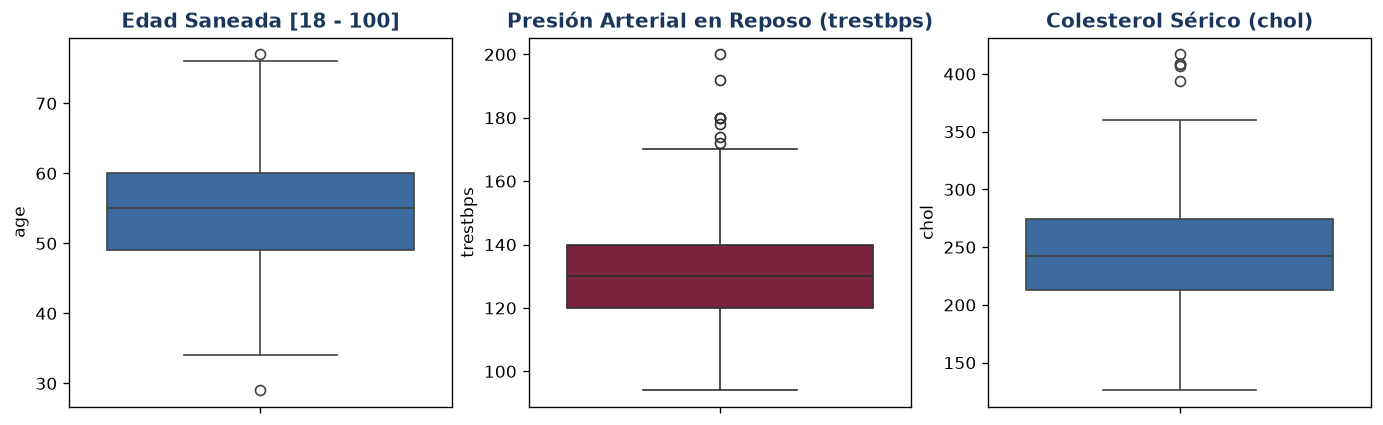

In [5]:
# Visualización de distribuciones y outliers controlados
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(y=df['age'], ax=axes[0], color='#2B6CB0')
axes[0].set_title('Edad Saneada [18 - 100]', fontweight='bold', color='#1A365D')
sns.boxplot(y=df['trestbps'], ax=axes[1], color='#8A1538')
axes[1].set_title('Presión Arterial en Reposo (trestbps)', fontweight='bold', color='#1A365D')
sns.boxplot(y=df['chol'], ax=axes[2], color='#2B6CB0')
axes[2].set_title('Colesterol Sérico (chol)', fontweight='bold', color='#1A365D')
plt.tight_layout()
plt.show()

## 4. Separación de Variables Predictoras (X) y Variable Objetivo (y) (Criterio 5 - Rúbrica)
**Fundamentación Técnica:** La variable `target` no debe figurar bajo ninguna circunstancia en la matriz de entrenamiento $X$. Si permaneciese, el clasificador aprendería una regla determinista trivial e idéntica a la etiqueta (*target leakage*), arrojando métricas de laboratorio del 100% que resultarían totalmente inútiles e inoperantes al enfrentarse a pacientes en la clínica real.

In [6]:
X = df.drop(columns=['target']).copy()
y = df['target'].copy()

print(f"Matriz de características X: {X.shape[0]} muestras x {X.shape[1]} predictoras")
print(f"Vector de etiquetas y: {y.shape[0]} muestras")
print("\nDistribución porcentual en y:")
print(y.value_counts(normalize=True).round(4) * 100)

Matriz de características X: 291 muestras x 13 predictoras
Vector de etiquetas y: 291 muestras

Distribución porcentual en y:
target
1    54.64
0    45.36
Name: proportion, dtype: float64


## 5. Partición Train / Test y Estratificación (Criterio 6 - Rúbrica)
- `test_size=0.20`: 20% para evaluación externa imparcial.
- `stratify=y`: Garantiza idéntica proporción de pacientes cardiópatas en Train y Test.
- `random_state=42`: Asegura la reproducibilidad científica del experimento.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Conjunto de entrenamiento (Train): X={X_train.shape}, y={y_train.shape}")
print(f"Conjunto de prueba (Test):         X={X_test.shape}, y={y_test.shape}")
print(f"\nPrevalencia positiva en Train: {(y_train.sum() / len(y_train) * 100):.2f}%")
print(f"Prevalencia positiva en Test:  {(y_test.sum() / len(y_test) * 100):.2f}%")

Conjunto de entrenamiento (Train): X=(232, 13), y=(232,)
Conjunto de prueba (Test):         X=(59, 13), y=(59,)

Prevalencia positiva en Train: 53.88%
Prevalencia positiva en Test:  54.24%


## 6. Transformación, Encoding y Escalamiento sin Data Leakage (Criterios 4 y 7 - Rúbrica)
- **OneHotEncoder** con `drop='first'` sobre las variables nominales policotómicas (`cp`, `restecg`, `slope`, `thal`) para eliminar la multicolinealidad estricta (*dummy variable trap*).
- **StandardScaler** sobre las continuas (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`).
- **Regla Inquebrantable:** El escalador y codificador aprenden sus parámetros (`.fit()`) **exclusivamente con `X_train`**. Sobre `X_test` únicamente se invoca `.transform()` utilizando la media y desviación estándar fijadas en entrenamiento.

In [8]:
nominal_cols = ['cp', 'restecg', 'slope', 'thal']
scaler_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
binary_cols = ['sex', 'fbs', 'exang', 'ca']

# 1. Codificación One-Hot ajustada exclusivamente en Train
ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
ohe.fit(X_train[nominal_cols])
ohe_names = ohe.get_feature_names_out(nominal_cols)

X_train_ohe = pd.DataFrame(ohe.transform(X_train[nominal_cols]), columns=ohe_names, index=X_train.index)
X_test_ohe = pd.DataFrame(ohe.transform(X_test[nominal_cols]), columns=ohe_names, index=X_test.index)

# 2. Escalamiento ajustado exclusivamente en Train
scaler = StandardScaler()
scaler.fit(X_train[scaler_cols])

X_train_scaled = pd.DataFrame(scaler.transform(X_train[scaler_cols]), columns=scaler_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test[scaler_cols]), columns=scaler_cols, index=X_test.index)

# 3. Consolidación de matrices listas para algoritmos predictivos
X_train_final = pd.concat([X_train_scaled, X_train[binary_cols], X_train_ohe], axis=1)
X_test_final = pd.concat([X_test_scaled, X_test[binary_cols], X_test_ohe], axis=1)

print(f"Dimensiones finales X_train: {X_train_final.shape}")
print(f"Dimensiones finales X_test:  {X_test_final.shape}")
X_train_final.head(3)

Dimensiones finales X_train: (232, 19)
Dimensiones finales X_test:  (59, 19)


,age,trestbps,chol,thalach,oldpeak,sex,fbs,exang,ca,cp_1.0,cp_2.0,cp_3.0,restecg_1.0,restecg_2.0,slope_1.0,slope_2.0,thal_1.0,thal_2.0,thal_3.0
124,-0.147206,-0.525765,0.725542,-2.375910,0.822948,1.0,0.0,1.0,2.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
33,0.327125,1.222410,-0.310181,0.637604,-0.880209,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
266,-0.265789,-0.243801,0.166252,0.506582,-0.880209,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


## 7. Tabla Oficial de Decisiones de Preprocesamiento (Criterio 8 - Rúbrica)

| Problema | Decisión | Justificación |
| :--- | :--- | :--- |
| **Valores faltantes** | Imputación por mediana en numéricas continuas y moda en categóricas/binarias. Eliminación de filas con target nulo. | La mediana es inmune a asimetrías y outliers. Imputar la variable objetivo sesgaría la veracidad clínica del clasificador. |
| **Duplicados** | Eliminación de las 6 filas idénticas redundantes (`drop_duplicates()`). | Filas duplicadas introducen sobreponderación artificial y sobreajuste hacia observaciones repetidas. |
| **Outliers / Inconsistencias** | Reemplazo por NaN de valores biológicamente imposibles (edad negativa, sex=-1, cp=7.25, etc.) y posterior imputación. | Evita distorsionar el cálculo de centroides y varianzas con valores corrompidos por errores de digitación o unidades. |
| **Variables eliminadas** | Ninguna columna eliminada; se conservaron las 13 predictoras del protocolo clínico. | Cada variable contiene información fisiológica crítica para el riesgo coronario (según el protocolo de Cleveland). |
| **Variables categóricas** | Identificación de nominales (`cp`, `restecg`, `slope`, `thal`) y binarias (`sex`, `fbs`, `exang`). | Previene que el algoritmo asuma un falso orden numérico intrínseco en variables sin jerarquía. |
| **Encoding** | One-Hot Encoding con `drop='first'` para variables nominales policotómicas. | Elimina la colinealidad exacta entre dummies y permite interpretar cada categoría respecto a la base. |
| **Normalización - Scaling** | `StandardScaler` con ajuste exclusivo sobre el conjunto Train (`fit` en train, `transform` en test). | Sitúa variables con distintas escalas (ej. colesterol ~250 vs depresión ST ~1.0) en media 0 y varianza 1 sin fuga de información (*data leakage*). |

---
### Pregunta de Reflexión Teórica:
**¿Por qué un buen modelo de Machine Learning depende de un adecuado proceso de preprocesamiento de datos?**

> **Respuesta:** En Machine Learning rige el principio fundamental *"Garbage In, Garbage Out"* (si entran datos basura, saldrán predicciones basura). Los algoritmos matemáticos no distinguen intuitivamente entre un error de captura (ej. edad negativa o unidades de texto), ruido de medición o un patrón médico real. Además, modelos sensibles a la distancia euclidiana (como KNN, SVM o Regresión Logística con regularización) son completamente dominados por variables con órdenes de magnitud altos (como el colesterol mg/dL) si no se estandarizan, ignorando factores biomédicos cruciales. Por último, un preprocesamiento riguroso garantiza la generalización real del modelo al blindar el conjunto de evaluación contra la fuga de datos (*data leakage*).